In [155]:
#----------------- ASSIGNMENT 16: Basic Exploratory Data Analysis -----------------------

In [157]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [159]:
# 1. Load the crop_yield.csv file into a Pandas DataFrame. 
crop_df=pd.read_csv(r"C:\Users\Administrator\Downloads\crop_yield.csv")

In [161]:
# 2. Display the first 10 rows to give an overview of the data. 
crop_df.head(10)

,FARM_ID,CROP_TYPE,YIELD_KG,AREA_ACRES,HARVEST_DATE,DISTRICT,SEASON,FERTILIZER_USED,YIELD_VALUE
0,F001,Wheat,1500.0,4.0,01/01/2023,Sialkot,Rabi,Yes,30000
1,F002,Wheat,1500.0,5.0,02/01/2023,Multan,Rabi,No,30000
2,F003,Wheat,2500.0,5.0,03/01/2023,Faisalabad,Rabi,Yes,50000
3,F004,Wheat,1500.0,NaN,04/01/2023,Multan,Rabi,Yes,30000
4,F005,Rice,1500.0,4.0,05/01/2023,Faisalabad,Rabi,No,30000
5,F006,Rice,2000.0,6.0,06/01/2023,Faisalabad,Rabi,Yes,40000
6,F007,Maize,1500.0,6.0,07/01/2023,Faisalabad,Rabi,No,30000
7,F008,Wheat,1500.0,5.0,08/01/2023,Lahore,Rabi,No,30000
8,F009,Wheat,2000.0,5.0,09/01/2023,Faisalabad,Rabi,Yes,40000
9,F010,Wheat,1500.0,3.0,10/01/2023,Faisalabad,Rabi,Yes,30000


In [163]:
# 3. Check for missing values in each column and display the result. 
crop_df.isnull().sum()

FARM_ID              0
CROP_TYPE            0
YIELD_KG           330
AREA_ACRES         144
HARVEST_DATE         0
DISTRICT           126
SEASON               0
FERTILIZER_USED    318
YIELD_VALUE          0
dtype: int64

In [165]:
# 4. View the data types of all columns.
crop_df.dtypes

FARM_ID             object
CROP_TYPE           object
YIELD_KG           float64
AREA_ACRES         float64
HARVEST_DATE        object
DISTRICT            object
SEASON              object
FERTILIZER_USED     object
YIELD_VALUE          int64
dtype: object

In [167]:
# 5. Get the statistical summary of all numeric columns. 
crop_df.describe()

,YIELD_KG,AREA_ACRES,YIELD_VALUE
count,2670.000000,2856.000000,3000.000000
mean,2014.232210,4.420168,39657.780000
std,407.846962,0.979259,8405.078755
min,1500.000000,3.000000,20068.000000
25%,1500.000000,4.000000,30000.000000
50%,2000.000000,4.000000,40000.000000
75%,2500.000000,5.000000,50000.000000
max,2500.000000,6.000000,50000.000000


In [169]:
# 6. Get the statistical summary of all objective columns. 
crop_df.describe(include='object')

,FARM_ID,CROP_TYPE,HARVEST_DATE,DISTRICT,SEASON,FERTILIZER_USED
count,3000,3000,3000,2874,3000,2682
unique,3000,4,3000,4,2,2
top,F001,Wheat,01/01/2023,Faisalabad,Rabi,Yes
freq,1,1158,1,936,1528,1776


In [171]:
# 7. Remove all rows where the YIELD_KG column has missing. 
crop_df = crop_df.dropna(subset=['YIELD_KG'])

In [173]:
# 8. Fill missing values in the AREA_ACRES column with the mean of that column.
crop_df['AREA_ACRES'] = crop_df['AREA_ACRES'].fillna(crop_df['AREA_ACRES'].mean())

In [175]:
# 9. Replace missing values in the DISTRICT column with the string 'Unknown'.
crop_df['DISTRICT'] = crop_df['DISTRICT'].fillna('Unknown')


In [177]:
# 10. Replace missing values in the FERTILIZER_USED column with the string 'No'. 
crop_df['FERTILIZER_USED'] = crop_df['FERTILIZER_USED'].fillna('No')


In [179]:
# 11. Replace missing values in the YIELD_VALUE column with the mean of the column. 
crop_df['YIELD_VALUE'] = crop_df['YIELD_VALUE'].fillna(crop_df['YIELD_VALUE'].mean())

In [181]:
# 12. Convert the HARVEST_DATE column to datetime format.
crop_df['HARVEST_DATE'] = pd.to_datetime(crop_df['HARVEST_DATE'], format='%d/%m/%Y', errors='coerce')


In [183]:
# 13. Remove the letter 'F' from the FARM_ID column and convert the result to an integer.
crop_df['FARM_ID'] = crop_df['FARM_ID'].str.replace('F', '').astype(int)

In [185]:
# 14. Re-check missing values in the data again after cleaning. 
crop_df.isnull().sum()

FARM_ID            0
CROP_TYPE          0
YIELD_KG           0
AREA_ACRES         0
HARVEST_DATE       0
DISTRICT           0
SEASON             0
FERTILIZER_USED    0
YIELD_VALUE        0
dtype: int64

In [187]:
# 15. Re-check the data types of all columns again after cleaning. 
crop_df.dtypes

FARM_ID                     int32
CROP_TYPE                  object
YIELD_KG                  float64
AREA_ACRES                float64
HARVEST_DATE       datetime64[ns]
DISTRICT                   object
SEASON                     object
FERTILIZER_USED            object
YIELD_VALUE                 int64
dtype: object

In [189]:
# 16. Calculate the total yield of each type of crop. 
crop_df.groupby('CROP_TYPE').agg({'YIELD_KG': 'sum'})

,YIELD_KG
CROP_TYPE,
Maize,1112500.0
Rice,1638000.0
Sugarcane,592000.0
Wheat,2035500.0


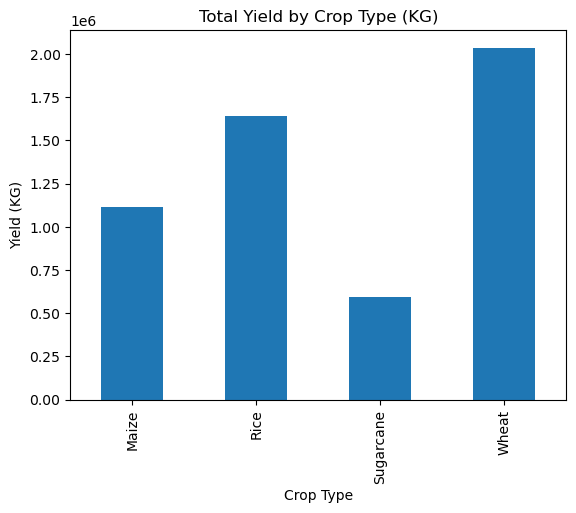

In [191]:
# 17. Plot a bar chart of Total Yield by Crop Type (KG). 
# Grouping Total yield:
crop_yield=crop_df.groupby('CROP_TYPE').agg({'YIELD_KG': 'sum'})
# Plotting the bar chart:
crop_yield.plot(kind='bar', legend=False)
plt.title('Total Yield by Crop Type (KG)')
plt.ylabel('Yield (KG)')
plt.xlabel('Crop Type')
plt.show()

In [192]:
# 18. Create a pivot table summarizing total yield by harvest date.
yield_pivot=crop_df.pivot_table(values='YIELD_KG', index='HARVEST_DATE',
aggfunc='sum')
yield_pivot

,YIELD_KG
HARVEST_DATE,
2023-01-01,1500.0
2023-01-02,1500.0
2023-01-03,2500.0
2023-01-04,1500.0
2023-01-05,1500.0
...,...
2031-03-15,1500.0
2031-03-16,2000.0
2031-03-17,2000.0


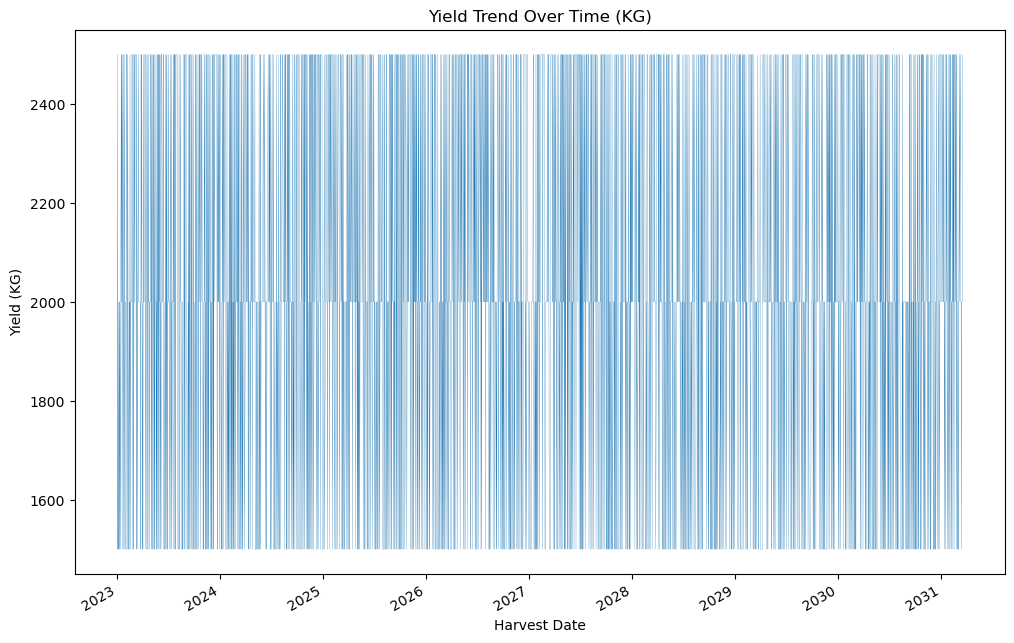

In [195]:
# 19. Plot a line chart showing the yield trend over time from the pivot table.
yield_pivot.plot(kind='line', legend=False, figsize=(12, 8), linewidth=0.2)
plt.title('Yield Trend Over Time (KG)')
plt.ylabel('Yield (KG)')
plt.xlabel('Harvest Date')
plt.savefig('crop_yield_trend.png')
plt.show()